In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

In [ ]:
# Load ECG dataset

In [10]:
# Load ECG dataset (without column headers)
df = pd.read_csv("ecg.csv", header=None)

print("Dataset Shape:", df.shape)
print(df.head())

# Separate features and labels
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values


Dataset Shape: (4998, 141)
        0         1         2         3         4         5         6    \
0 -0.112522 -2.827204 -3.773897 -4.349751 -4.376041 -3.474986 -2.181408   
1 -1.100878 -3.996840 -4.285843 -4.506579 -4.022377 -3.234368 -1.566126   
2 -0.567088 -2.593450 -3.874230 -4.584095 -4.187449 -3.151462 -1.742940   
3  0.490473 -1.914407 -3.616364 -4.318823 -4.268016 -3.881110 -2.993280   
4  0.800232 -0.874252 -2.384761 -3.973292 -4.338224 -3.802422 -2.534510   

        7         8         9    ...       131       132       133       134  \
0 -1.818286 -1.250522 -0.477492  ...  0.792168  0.933541  0.796958  0.578621   
1 -0.992258 -0.754680  0.042321  ...  0.538356  0.656881  0.787490  0.724046   
2 -1.490659 -1.183580 -0.394229  ...  0.886073  0.531452  0.311377 -0.021919   
3 -1.671131 -1.333884 -0.965629  ...  0.350816  0.499111  0.600345  0.842069   
4 -1.783423 -1.594450 -0.753199  ...  1.148884  0.958434  1.059025  1.371682   

        135       136       137       138

In [11]:

# Separate normal and abnormal ECG signals
NORMAL_LABEL = 1

normal_data = X[y == NORMAL_LABEL]
abnormal_data = X[y != NORMAL_LABEL]

print("Normal ECG records:", len(normal_data))
print("Abnormal ECG records:", len(abnormal_data))

Normal ECG records: 2919
Abnormal ECG records: 2079


In [12]:
# Normalize ECG signals

In [13]:
scaler = MinMaxScaler()

normal_data = scaler.fit_transform(normal_data)
abnormal_data = scaler.transform(abnormal_data)

all_data = np.vstack((normal_data, abnormal_data))
all_labels = np.concatenate((
    np.zeros(len(normal_data)),
    np.ones(len(abnormal_data))
))

In [14]:
# Split training and testing data

In [15]:
X_train, X_val = train_test_split(
    normal_data,
    test_size=0.2,
    random_state=42
)

X_test = all_data
y_test = all_labels

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

Training data: (2335, 140)
Validation data: (584, 140)
Testing data: (4998, 140)


In [16]:
# Encoder implementation

In [17]:
input_dim = X_train.shape[1]

input_layer = Input(shape=(input_dim,))

encoded = Dense(64, activation="relu")(input_layer)
encoded = Dense(32, activation="relu")(encoded)

latent = Dense(16, activation="relu")(encoded)

In [18]:
# Decoder implementation

In [19]:
decoded = Dense(32, activation="relu")(latent)
decoded = Dense(64, activation="relu")(decoded)

output_layer = Dense(input_dim, activation="sigmoid")(decoded)

In [20]:
# Build Autoencoder model

In [21]:
autoencoder = Model(input_layer, output_layer)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 140)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           9,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 32)                  │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 140)                 │           9,100 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,388 (91.36 KB)

 Trainable params: 23,388 (91.36 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
# Compile the model

In [23]:
autoencoder.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

In [24]:
# Train the Autoencoder

In [25]:
history = autoencoder.fit(
    X_train,
    X_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, X_val),
    verbose=1
)

Epoch 1/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - loss: 0.0133 - mae: 0.0842 - val_loss: 0.0092 - val_mae: 0.0658
Epoch 2/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0079 - mae: 0.0615 - val_loss: 0.0065 - val_mae: 0.0552
Epoch 3/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0054 - mae: 0.0513 - val_loss: 0.0046 - val_mae: 0.0475
Epoch 4/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0042 - mae: 0.0447 - val_loss: 0.0036 - val_mae: 0.0402
Epoch 5/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0034 - mae: 0.0391 - val_loss: 0.0031 - val_mae: 0.0378
Epoch 6/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0031 - mae: 0.0374 - val_loss: 0.0029 - val_mae: 0.0362
Epoch 7/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0029 - mae: 0.0361 - val_loss: 0.0027 - val_mae: 0.0350
Epoch 8/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0027 - mae: 0.0351 - val_loss: 0.0026 - val_mae: 0.0343
Epoch 9/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0026 -

In [26]:
# Calculate reconstruction errors

In [27]:
reconstructed = autoencoder.predict(X_test)

reconstruction_errors = np.mean(
    np.square(X_test - reconstructed),
    axis=1
)

print("Reconstruction Errors:")
print(reconstruction_errors[:10])

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
Reconstruction Errors:
[0.00076303 0.00100083 0.0012771  0.0012205  0.00122547 0.00142668
 0.00056748 0.00099225 0.00221325 0.00347105]


In [28]:
# Set anomaly detection threshold

In [29]:
val_reconstructed = autoencoder.predict(X_val)

val_errors = np.mean(
    np.square(X_val - val_reconstructed),
    axis=1
)

threshold = np.percentile(val_errors, 95)

print("Anomaly Threshold:", threshold)

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
Anomaly Threshold: 0.00382170402583858


In [30]:
# Identify normal and abnormal ECG signals

In [31]:
predictions = reconstruction_errors > threshold

for i in range(10):
    if predictions[i]:
        print("ECG", i, ": Abnormal")
    else:
        print("ECG", i, ": Normal")

ECG 0 : Normal
ECG 1 : Normal
ECG 2 : Normal
ECG 3 : Normal
ECG 4 : Normal
ECG 5 : Normal
ECG 6 : Normal
ECG 7 : Normal
ECG 8 : Normal
ECG 9 : Normal


In [32]:
# Display original and reconstructed ECG signals

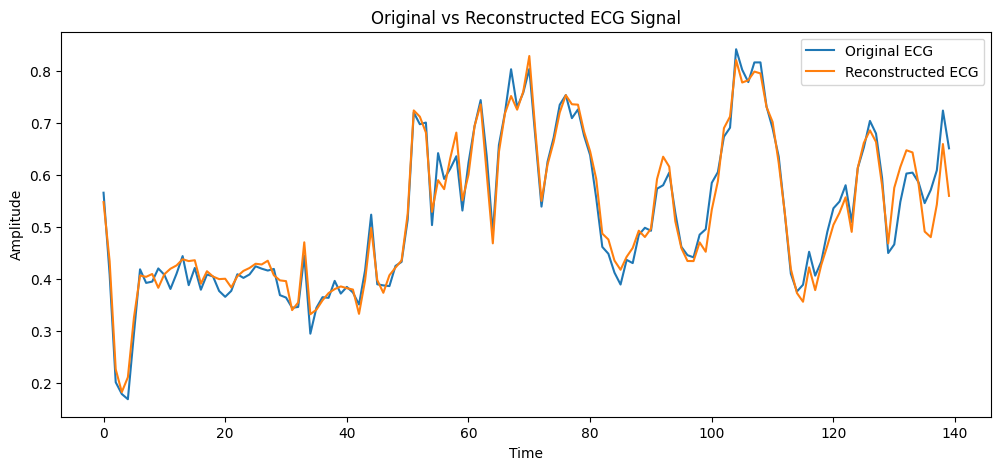

In [33]:
sample = X_test[0]

reconstructed_sample = autoencoder.predict(
    sample.reshape(1, -1),
    verbose=0
)[0]

plt.figure(figsize=(12, 5))

plt.plot(sample, label="Original ECG")
plt.plot(reconstructed_sample, label="Reconstructed ECG")

plt.title("Original vs Reconstructed ECG Signal")
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.legend()
plt.show()

In [34]:
# Display reconstruction errors

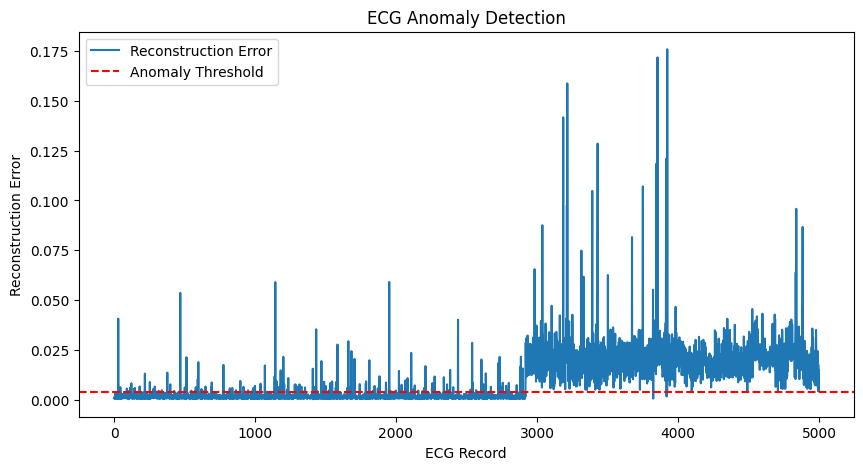

In [35]:
plt.figure(figsize=(10, 5))

plt.plot(reconstruction_errors, label="Reconstruction Error")
plt.axhline(y=threshold, color="red", linestyle="--",
            label="Anomaly Threshold")

plt.title("ECG Anomaly Detection")
plt.xlabel("ECG Record")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.show()

In [36]:
# Display training and validation loss

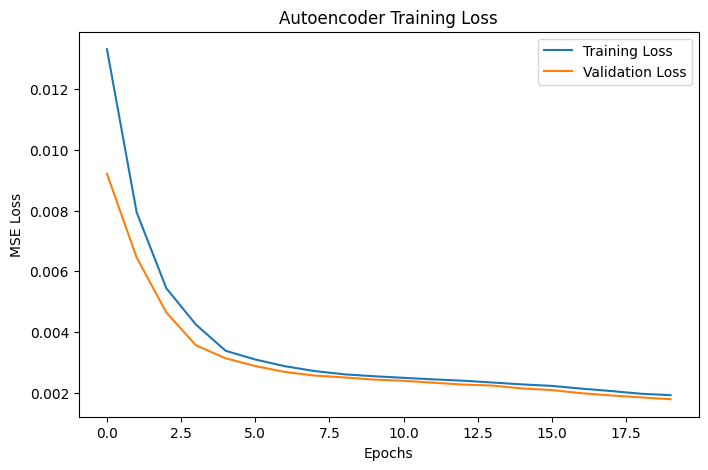

In [37]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Autoencoder Training Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()